### PIPELINE UTAMA COMPUTER VISION PANGANITA – YOLO26n DETECTION

Notebook ini merupakan eksperimen utama Computer Vision PANGANITA untuk mendeteksi bahan pangan dari gambar menggunakan YOLO26n Detection.

**Model dan teknologi:**
- Model pretrained: `yolo26n.pt`
- Framework: Ultralytics
- Bahasa: Python
- Image size: 640 × 640
- Training: 100 epoch, batch size 4, CPU.

**Tahapan eksperimen:**
1. Pemeriksaan dan persiapan dataset.
2. Konversi anotasi YOLO Segmentation menjadi YOLO Detection (bounding box).
3. Fine-tuning model YOLO26n Detection.
4. Pengujian menggunakan model `best.pt`.
5. Pengujian deteksi pada gambar bahan pangan.
6. Visualisasi hasil deteksi dan confidence score.

**15 kelas bahan pangan:**

Wortel, Udang, Singkong, Pisang, Ubi Jalar, Jagung, Tomat, Ikan Lele, Ikan Kembung, Ikan Tongkol, Ikan Gurame, Bayam, Kangkung, Buah Naga, dan Telur Ayam Ras.

**Output:** Nama kelas, bounding box, confidence score, dan gambar hasil deteksi.

Notebook ini menjadi pipeline utama pengembangan fitur Pindai Panen PANGANITA.

##### 1. Pemeriksaan lokasi proyek dan dataset
Bagian ini memastikan notebook dijalankan dari folder proyek panganita-cv serta memeriksa lokasi dataset sumber dan dataset hasil konversi. Pastikan Path.cwd() menunjuk ke folder proyek yang benar sebelum menjalankan sel berikutnya.

In [1]:
from pathlib import Path

ROOT = Path.cwd()

print("PROYEK:", ROOT)
print("DATASET SEG:", ROOT / "dataset-yolo-stratified")
print("DATASET DETECT:", ROOT / "dataset-yolo-detect")

PROYEK: c:\Users\LENOVO\Music\panganita-cv
DATASET SEG: c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified
DATASET DETECT: c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-detect


##### 2. Menyiapkan dataset Detection dari anotasi Segmentation
Kode membaca dataset YOLO Segmentation yang sudah dibagi menjadi train, val, dan test, lalu mengubah setiap anotasi polygon menjadi bounding box format YOLO Detection (class_id x_center y_center width height). Foto dan pembagian data disalin ke folder baru dataset-yolo-detect, sehingga dataset segmentation asli tetap dipertahankan. Di akhir proses, kode membuat data.yaml berisi lokasi dataset dan 15 nama kelas serta mencetak jumlah foto dan objek per split. Jalankan setelah dataset sumber dan seluruh label polygon tersedia.

**Konversi Segmentation ke Detection**
- Membaca 151 foto dari dataset segmentation.
- Mengubah setiap polygon menjadi bounding box.
- Mempertahankan pembagian train, val, dan test.
- Mempertahankan 15 kelas pangan.
- Membuat dataset baru tanpa mengubah dataset segmentation.

In [2]:

import shutil
from pathlib import Path

# ==========================================
# 1. KONFIGURASI
# ==========================================

ROOT = Path.cwd()

SOURCE = ROOT / "dataset-yolo-stratified"
OUTPUT = ROOT / "dataset-yolo-detect"

CLASSES = [
    "wortel",
    "udang",
    "singkong",
    "pisang",
    "ubi_jalar",
    "jagung",
    "tomat",
    "ikan_lele",
    "ikan_kembung",
    "ikan_tongkol",
    "ikan_gurame",
    "bayam",
    "kangkung",
    "buah_naga",
    "telur_ayam_ras"
]

SPLITS = ["train", "val", "test"]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

if not (SOURCE / "data.yaml").exists():
    raise FileNotFoundError("Dataset segmentation tidak ditemukan!")

# ==========================================
# 2. SIAPKAN FOLDER BARU
# ==========================================

if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

for split in SPLITS:
    (OUTPUT / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (OUTPUT / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

# ==========================================
# 3. KONVERSI POLYGON KE BOUNDING BOX
# ==========================================

total_images = 0
total_objects = 0

for split in SPLITS:

    image_folder = SOURCE / "images" / split
    label_folder = SOURCE / "labels" / split

    images = sorted([
        p for p in image_folder.iterdir()
        if p.suffix.lower() in EXTENSIONS
    ])

    for image_path in images:

        seg_path = label_folder / f"{image_path.stem}.txt"

        if not seg_path.exists():
            raise FileNotFoundError(
                f"Label tidak ditemukan: {seg_path}"
            )

        detect_lines = []

        for line_number, line in enumerate(
            seg_path.read_text(encoding="utf-8").splitlines(), 1
        ):

            values = line.split()

            if not values:
                continue

            if len(values) < 7 or (len(values) - 1) % 2 != 0:
                raise ValueError(
                    f"Polygon tidak valid: {seg_path}, "
                    f"baris {line_number}"
                )

            class_id = int(values[0])

            if not 0 <= class_id < len(CLASSES):
                raise ValueError(
                    f"Class ID tidak valid: {seg_path}"
                )

            coords = [float(v) for v in values[1:]]

            if not all(0 <= v <= 1 for v in coords):
                raise ValueError(
                    f"Koordinat tidak valid: {seg_path}"
                )

            xs = coords[0::2]
            ys = coords[1::2]

            x_min, x_max = min(xs), max(xs)
            y_min, y_max = min(ys), max(ys)

            x_center = (x_min + x_max) / 2
            y_center = (y_min + y_max) / 2

            width = x_max - x_min
            height = y_max - y_min

            if width <= 0 or height <= 0:
                raise ValueError(
                    f"Bounding box tidak valid: {seg_path}"
                )

            detect_lines.append(
                f"{class_id} "
                f"{x_center:.6f} "
                f"{y_center:.6f} "
                f"{width:.6f} "
                f"{height:.6f}"
            )

        shutil.copy2(
            image_path,
            OUTPUT / "images" / split / image_path.name
        )

        detect_path = (
            OUTPUT / "labels" / split /
            f"{image_path.stem}.txt"
        )

        detect_path.write_text(
            "\n".join(detect_lines) + "\n",
            encoding="utf-8"
        )

        total_images += 1
        total_objects += len(detect_lines)

# ==========================================
# 4. BUAT DATA.YAML
# ==========================================

yaml_content = [
    f"path: '{OUTPUT.as_posix()}'",
    "train: images/train",
    "val: images/val",
    "test: images/test",
    "",
    "names:"
]

for i, name in enumerate(CLASSES):
    yaml_content.append(f"  {i}: {name}")

(OUTPUT / "data.yaml").write_text(
    "\n".join(yaml_content) + "\n",
    encoding="utf-8"
)

# ==========================================
# 5. LAPORAN
# ==========================================

print("\n======= DATASET YOLO DETECT =======")

for split in SPLITS:

    image_count = len(list(
        (OUTPUT / "images" / split).glob("*")
    ))

    object_count = sum(
        len(p.read_text(encoding="utf-8").splitlines())
        for p in (OUTPUT / "labels" / split).glob("*.txt")
    )

    print(
        f"{split.upper():5}: "
        f"{image_count} foto | {object_count} objek"
    )

print("----------------------------------")
print("Total foto:", total_images)
print("Total objek:", total_objects)
print("Jumlah kelas:", len(CLASSES))
print("Lokasi:", OUTPUT)
print("\nKONVERSI DETECTION SELESAI!")



======= DATASET YOLO DETECT =======
TRAIN: 102 foto | 172 objek
VAL  : 32 foto | 57 objek
TEST : 17 foto | 27 objek
----------------------------------
Total foto: 151
Total objek: 256
Jumlah kelas: 15
Lokasi: c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-detect

KONVERSI DETECTION SELESAI!


##### 3. Fine-tuning model YOLO26n Detection
Tahap ini memuat bobot pretrained yolo26n.pt, kemudian melatih ulang model untuk mengenali 15 kelas pangan PANGANITA menggunakan dataset-yolo-detect/data.yaml. Konfigurasi eksperimen pada kode: 100 epoch, ukuran gambar 640, batch 4, CPU, optimizer AdamW, learning rate awal 0,001, dan seed 42. Ultralytics menyimpan checkpoint best.pt dan last.pt serta grafik training di folder runs/yolo26n_detect_v1. Catat hasil aktual dari log training; konfigurasi yang diminta tidak otomatis membuktikan bahwa seluruh epoch selesai.

In [3]:

from ultralytics import YOLO
from pathlib import Path
import torch

# =====================================
# 1. KONFIGURASI
# =====================================

ROOT = Path.cwd()

DATA_YAML = (
    ROOT / "dataset-yolo-detect" / "data.yaml"
)

PROJECT = ROOT / "runs"
NAME = "yolo26n_detect_v1"

# =====================================
# 2. MUAT PRETRAINED MODEL
# =====================================

model = YOLO("yolo26n.pt")

print("YOLO26n Detect berhasil dimuat!")
print("Jumlah kelas pretrained:", len(model.names))
print("Device: CPU")

# =====================================
# 3. TRAINING
# =====================================

results = model.train(
    data=str(DATA_YAML),

    epochs=100,
    imgsz=640,
    batch=4,

    device="cpu",
    workers=0,

    patience=20,

    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,

    project=str(PROJECT),
    name=NAME,

    save=True,
    plots=True,
    verbose=True,
    seed=42
)

print("\n================================")
print("TRAINING YOLO26 DETECT SELESAI!")
print("================================")

print("Lokasi hasil:", PROJECT / NAME)
print("Best model:", PROJECT / NAME / "weights" / "best.pt")
print("Last model:", PROJECT / NAME / "weights" / "last.pt")


YOLO26n Detect berhasil dimuat!
Jumlah kelas pretrained: 80
Device: CPU
New https://pypi.org/project/ultralytics/8.4.193 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.192  Python-3.12.7 torch-2.15.0+cpu CPU (12th Gen Intel Core i5-12450H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-detect\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, 

### 4. Uji awal model terbaik pada satu foto
Kode memeriksa keberadaan best.pt, mencari foto di folder foto-mentah, lalu menjalankan inferensi pada satu foto pertama dengan confidence threshold 0,25. Hasil divisualisasikan dengan bounding box dan label kelas, kemudian nama kelas serta confidence setiap objek dicetak. Output disimpan oleh Ultralytics pada folder runs/detect/uji_deteksi_panganita. Tahap ini merupakan uji fungsional awal, bukan evaluasi metrik menyeluruh.

Lokasi model: c:\Users\LENOVO\Music\panganita-cv\runs\yolo26n_detect_v1\weights\best.pt
Model tersedia: True
Jumlah gambar pengujian: 162

image 1/1 c:\Users\LENOVO\Music\panganita-cv\foto-mentah\013.jpg: 640x640 1 telur_ayam_ras, 559.9ms
Speed: 66.0ms preprocess, 559.9ms inference, 93.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to E:\my-next-app\runs\detect\runs\detect\uji_deteksi_panganita


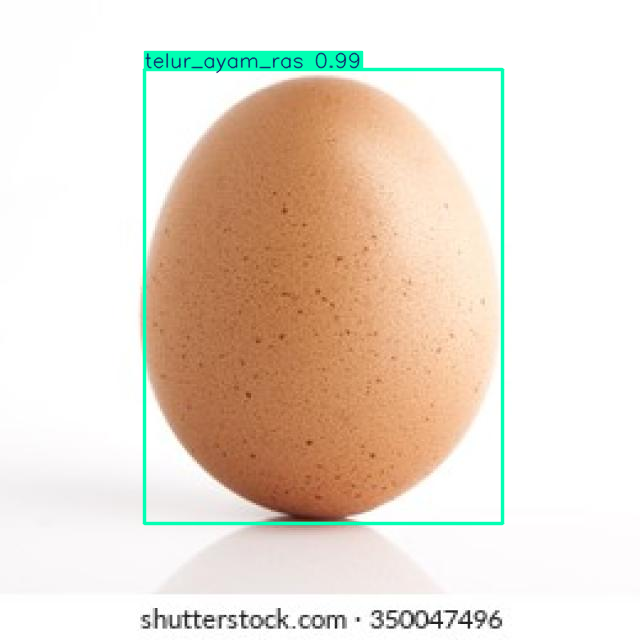


HASIL DETEKSI
Gambar: 013.jpg
Objek: telur_ayam_ras | Confidence: 0.986


In [4]:

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

# 1. Lokasi model hasil training
best_model = Path(PROJECT) / str(NAME) / "weights" / "best.pt"

print("Lokasi model:", best_model)
print("Model tersedia:", best_model.exists())

# 2. Cari gambar untuk pengujian
foto_folder = Path("foto-mentah")

images = []
for ext in ["*.jpg", "*.jpeg", "*.png", "*.webp"]:
    images.extend(foto_folder.glob(ext))

print("Jumlah gambar pengujian:", len(images))

# 3. Periksa sebelum menjalankan deteksi
if not best_model.exists():
    print("ERROR: best.pt tidak ditemukan!")

elif len(images) == 0:
    print("ERROR: Tidak ada gambar di folder foto-mentah!")

else:
    # 4. Muat model hasil training
    model = YOLO(str(best_model))

    # 5. Jalankan deteksi pada gambar pertama
    results = model.predict(
        source=str(images[0]),
        conf=0.25,
        save=True,
        project="runs/detect",
        name="uji_deteksi_panganita",
        exist_ok=True
    )

    # 6. Tampilkan hasil deteksi
    result = results[0]

    annotated = result.plot()
    display(Image.fromarray(annotated[:, :, ::-1]))

    # 7. Tampilkan informasi objek
    print("\nHASIL DETEKSI")
    print("Gambar:", images[0].name)

    if result.boxes is not None and len(result.boxes) > 0:
        for box in result.boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])

            print(
                "Objek:", result.names[class_id],
                "| Confidence:", round(confidence, 4)
            )
    else:
        print("Belum ada objek yang terdeteksi.")


c:\Users\LENOVO\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\LENOVO\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


ROOT: C:\Users\LENOVO\Music\panganita-cv
MODEL: C:\Users\LENOVO\Music\panganita-cv\runs\yolo26n_detect_v1\weights\best.pt
FOTO UJI: C:\Users\LENOVO\Music\panganita-cv\foto-mentah
OUTPUT: C:\Users\LENOVO\Music\panganita-cv\runs\prediksi_foto_baru_detect

Model berhasil dimuat!
Jumlah kelas: 15

0: 640x640 1 telur_ayam_ras, 240.4ms
1: 640x640 8 jagungs, 240.4ms
2: 640x640 (no detections), 240.4ms
3: 640x640 2 wortels, 240.4ms
4: 640x640 1 wortel, 8 telur_ayam_rass, 240.4ms
5: 640x640 1 pisang, 240.4ms
6: 640x640 5 pisangs, 240.4ms
7: 640x640 18 pisangs, 240.4ms
8: 640x640 2 pisangs, 240.4ms
9: 640x640 1 kangkung, 240.4ms
10: 640x640 1 bayam, 240.4ms
11: 640x640 1 bayam, 240.4ms
12: 640x640 1 kangkung, 240.4ms
13: 640x640 1 bayam, 240.4ms
14: 640x640 1 bayam, 240.4ms
15: 640x640 3 bayams, 240.4ms
16: 640x640 3 bayams, 240.4ms
17: 640x640 1 bayam, 240.4ms
18: 640x640 1 bayam, 240.4ms
19: 640x640 1 bayam, 240.4ms
20: 640x640 1 bayam, 240.4ms
21: 640x640 2 bayams, 240.4ms
22: 640x640 1 bayam

,foto,kelas,confidence
0,013.jpg,telur_ayam_ras,0.9860
1,13572630374-img-20260611-wa0001.jpg,jagung,0.9654
2,13572630374-img-20260611-wa0001.jpg,jagung,0.9168
3,13572630374-img-20260611-wa0001.jpg,jagung,0.8446
4,13572630374-img-20260611-wa0001.jpg,jagung,0.7847
...,...,...,...
351,wortel8.jpg,wortel,0.9085
352,wortel8.jpg,wortel,0.8888
353,wortel9.jpg,wortel,0.9467
354,wortel9.jpg,wortel,0.9085



Jumlah foto diuji: 162
Total objek terdeteksi: 356
Laporan CSV: C:\Users\LENOVO\Music\panganita-cv\runs\prediksi_foto_baru_detect\laporan_deteksi.csv

Foto: 013.jpg


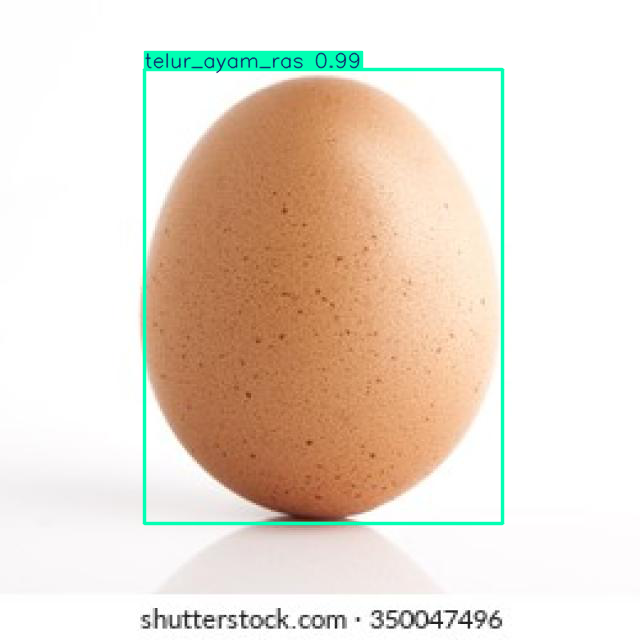


Foto: 13572630374-img-20260611-wa0001.jpg


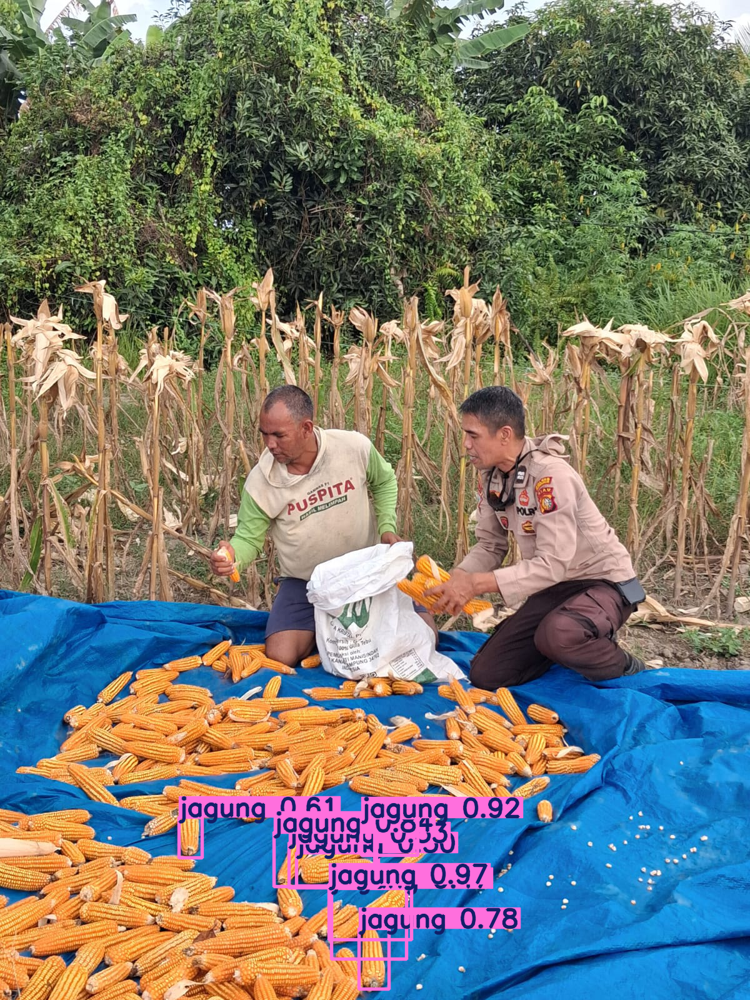


Foto: 63a6193568e2e.jpg


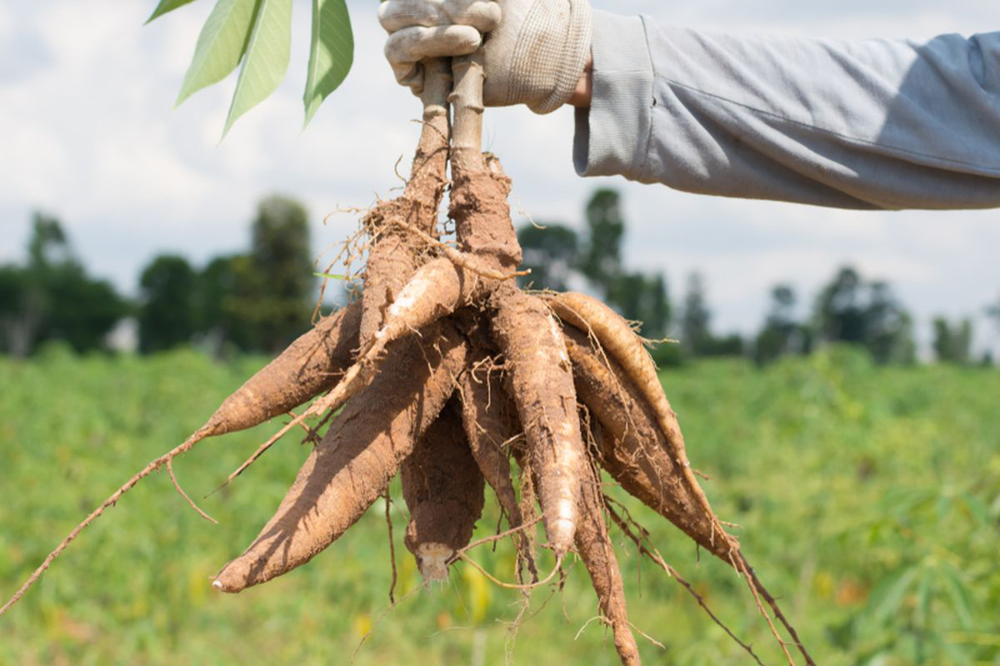


Foto: 63ec97aa28ed5.jpg


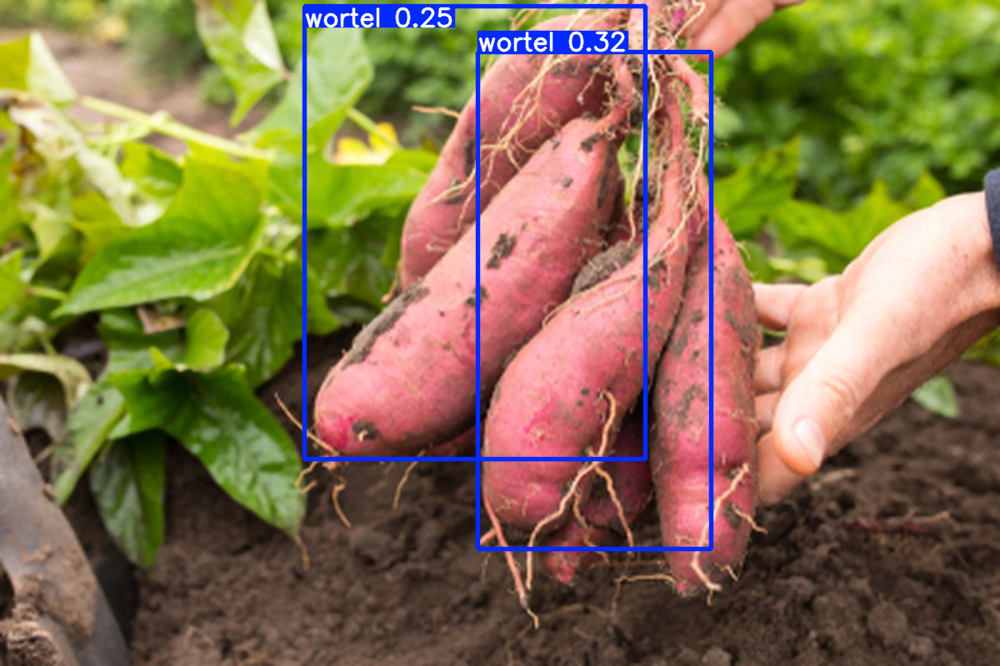


Foto: 66d9c670-422b-4d25-a09f-0ae50ed91dbb_jpg.rf.7b0f2b5abd70eab1664bccbbf91262ca.jpg


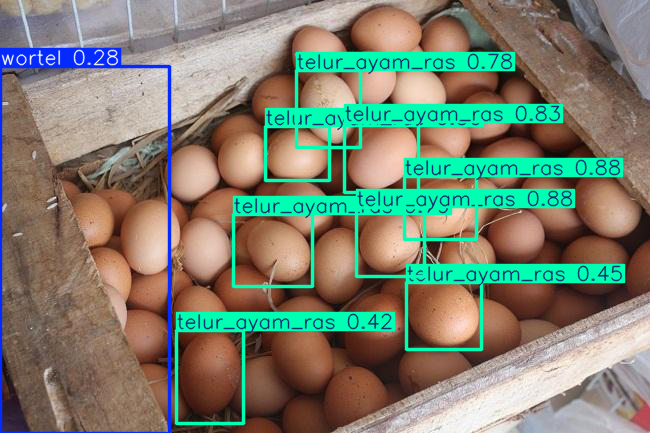


PENGUJIAN SELESAI!
Lokasi hasil: C:\Users\LENOVO\Music\panganita-cv\runs\prediksi_foto_baru_detect


In [5]:

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import pandas as pd

# =====================================
# 1. KONFIGURASI LOKASI PANGANITA
# =====================================

ROOT = Path(
    r"C:\Users\LENOVO\Music\panganita-cv"
)

MODEL_PATH = (
    ROOT / "runs" / "yolo26n_detect_v1"
    / "weights" / "best.pt"
)

TEST_FOLDER = ROOT / "foto-mentah"

OUTPUT_FOLDER = (
    ROOT / "runs" / "prediksi_foto_baru_detect"
)

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("MODEL:", MODEL_PATH)
print("FOTO UJI:", TEST_FOLDER)
print("OUTPUT:", OUTPUT_FOLDER)

# =====================================
# 2. VALIDASI FILE
# =====================================

if not MODEL_PATH.exists():
    raise FileNotFoundError("best.pt tidak ditemukan!")

if not TEST_FOLDER.exists():
    raise FileNotFoundError("Folder foto-mentah tidak ditemukan!")

photos = sorted([
    p for p in TEST_FOLDER.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
])

if not photos:
    raise ValueError("Tidak ada foto untuk diuji!")

# =====================================
# 3. MUAT MODEL
# =====================================

model = YOLO(str(MODEL_PATH))

print("\nModel berhasil dimuat!")
print("Jumlah kelas:", len(model.names))

# =====================================
# 4. PREDIKSI
# =====================================

results = model.predict(
    source=[str(p) for p in photos],
    conf=0.25,
    imgsz=640,
    device="cpu",
    save=True,
    project=str(ROOT / "runs"),
    name="prediksi_foto_baru_detect",
    exist_ok=True
)

# =====================================
# 5. RINGKASAN HASIL
# =====================================

laporan = []

for result in results:

    if result.boxes is None:
        continue

    for box in result.boxes:

        class_id = int(box.cls.item())
        confidence = float(box.conf.item())

        laporan.append({
            "foto": Path(result.path).name,
            "kelas": model.names[class_id],
            "confidence": round(confidence, 4)
        })

df_hasil = pd.DataFrame(
    laporan,
    columns=["foto", "kelas", "confidence"]
)

display(df_hasil)

print("\nJumlah foto diuji:", len(results))
print("Total objek terdeteksi:", len(df_hasil))

# =====================================
# 6. SIMPAN LAPORAN CSV
# =====================================

csv_path = OUTPUT_FOLDER / "laporan_deteksi.csv"

df_hasil.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("Laporan CSV:", csv_path)

# =====================================
# 7. TAMPILKAN CONTOH HASIL
# =====================================

for result in results[:5]:

    print("\nFoto:", Path(result.path).name)

    annotated = result.plot()

    display(
        Image.fromarray(annotated[:, :, ::-1].copy())
    )

print("\nPENGUJIAN SELESAI!")
print("Lokasi hasil:", OUTPUT_FOLDER)


##### 6. Antarmuka upload foto untuk demonstrasi inferensi
Sel ini membuat antarmuka sederhana di Jupyter menggunakan ipywidgets.FileUpload dan tombol deteksi. Foto yang diunggah disimpan ke runs/upload_uji_detect/foto, diproses dengan model best.pt, lalu hasil anotasi disimpan ke runs/upload_uji_detect/hasil. Kode juga menyusun laporan prediksi berisi nama foto, kelas, dan confidence. Fitur ini digunakan untuk demonstrasi pipeline input gambar hingga hasil prediksi; antarmuka ini berjalan di notebook, bukan halaman web Next.js.

In [ ]:

# ============================================================
# PANGANITA - UPLOAD FOTO & DETEKSI YOLO26
# ============================================================

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import ipywidgets as widgets
import pandas as pd
import numpy as np
import re

# ============================================================
# 1. KONFIGURASI LOKASI PROYEK
# ============================================================

ROOT = Path(r"C:\Users\LENOVO\Music\panganita-cv")

MODEL_PATH = (
    ROOT / "runs" / "yolo26n_detect_v1"
    / "weights" / "best.pt"
)

UPLOAD_FOLDER = ROOT / "runs" / "upload_uji_detect" / "foto"
OUTPUT_FOLDER = ROOT / "runs" / "upload_uji_detect" / "hasil"

UPLOAD_FOLDER.mkdir(parents=True, exist_ok=True)
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. VALIDASI DAN MUAT MODEL
# ============================================================

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model tidak ditemukan: {MODEL_PATH}"
    )

model = YOLO(str(MODEL_PATH))

print("====================================")
print(" MODEL YOLO26 PANGANITA SIAP")
print("====================================")
print("Lokasi model:", MODEL_PATH)
print("Jumlah kelas:", len(model.names))
print("Kelas:", list(model.names.values()))
print("Device: CPU")

# ============================================================
# 3. KOMPONEN UPLOAD FOTO
# ============================================================

uploader = widgets.FileUpload(
    accept="image/*",
    multiple=True,
    description="Pilih Foto"
)

button = widgets.Button(
    description="DETEKSI FOTO",
    button_style="success",
    icon="search",
    layout=widgets.Layout(width="180px")
)

output = widgets.Output()

# ============================================================
# 4. MEMBACA FILE UPLOAD (IPYWIDGETS 7 DAN 8)
# ============================================================

def get_uploaded_files(value):

    if isinstance(value, dict):
        return [
            (name, item["content"])
            for name, item in value.items()
        ]

    return [
        (item["name"], item["content"])
        for item in value
    ]

# ============================================================
# 5. PROSES DETEKSI
# ============================================================

def predict_uploaded(b):

    with output:
        output.clear_output(wait=True)

        uploaded = get_uploaded_files(uploader.value)

        if not uploaded:
            print("Silakan upload foto terlebih dahulu!")
            return

        laporan = []

        for filename, content in uploaded:

            safe_name = re.sub(
                r"[^a-zA-Z0-9._-]",
                "_",
                Path(filename).name
            )

            image_path = UPLOAD_FOLDER / safe_name

            # Simpan foto upload
            image_path.write_bytes(bytes(content))

            print(f"\nMemproses: {filename}")

            try:

                # Prediksi menggunakan YOLO26 Detection
                results = model.predict(
                    source=str(image_path),
                    conf=0.25,
                    imgsz=640,
                    device="cpu",
                    save=False,
                    verbose=False
                )

                result = results[0]

                jumlah_objek = 0

                if result.boxes is not None:

                    for box in result.boxes:

                        class_id = int(box.cls.item())
                        confidence = float(box.conf.item())

                        nama_kelas = model.names[class_id]

                        laporan.append({
                            "foto": filename,
                            "kelas": nama_kelas,
                            "confidence": round(confidence, 4)
                        })

                        jumlah_objek += 1

                print("Jumlah objek:", jumlah_objek)

                if jumlah_objek == 0:
                    print("Tidak ada objek terdeteksi.")

                # Visualisasi hasil
                annotated = result.plot()

                # Konversi BGR ke RGB
                annotated_rgb = np.ascontiguousarray(
                    annotated[:, :, ::-1]
                )

                # Simpan hasil visual
                output_path = (
                    OUTPUT_FOLDER /
                    f"{image_path.stem}_deteksi.jpg"
                )

                Image.fromarray(annotated_rgb).save(
                    output_path,
                    quality=95
                )

                # Tampilkan hasil
                display(
                    Image.fromarray(annotated_rgb)
                )

                print("Hasil disimpan:", output_path)

            except Exception as e:
                print("Gagal memproses foto:", str(e))

        # Tabel hasil
        print("\n====================================")
        print("       HASIL DETEKSI PANGANITA")
        print("====================================")

        df = pd.DataFrame(
            laporan,
            columns=["foto", "kelas", "confidence"]
        )

        if not df.empty:

            df["confidence (%)"] = (
                df["confidence"] * 100
            ).round(2)

            display(
                df[["foto", "kelas", "confidence (%)"]]
            )

            print("Total objek terdeteksi:", len(df))

        else:
            print("Belum ada objek yang berhasil dideteksi.")

        # Simpan laporan
        csv_path = OUTPUT_FOLDER / "laporan_deteksi.csv"

        df.to_csv(
            csv_path,
            index=False,
            encoding="utf-8-sig"
        )

        print("\nLaporan:", csv_path)
        print("Pengujian selesai!")

# ============================================================
# 6. HUBUNGKAN TOMBOL
# ============================================================

button.on_click(predict_uploaded)

# ============================================================
# 7. TAMPILKAN INTERFACE
# ============================================================

display(widgets.VBox([
    widgets.HTML(
        """
        <h3>Pengujian YOLO26 Detection - PANGANITA</h3>
        <p>Upload foto hasil panen, bahan pangan, atau telur.
        Kemudian klik tombol deteksi.</p>
        """
    ),
    uploader,
    button,
    output
]))


 MODEL YOLO26 PANGANITA SIAP
Lokasi model: C:\Users\LENOVO\Music\panganita-cv\runs\yolo26n_detect_v1\weights\best.pt
Jumlah kelas: 15
Kelas: ['wortel', 'udang', 'singkong', 'pisang', 'ubi_jalar', 'jagung', 'tomat', 'ikan_lele', 'ikan_kembung', 'ikan_tongkol', 'ikan_gurame', 'bayam', 'kangkung', 'buah_naga', 'telur_ayam_ras']
Device: CPU


##### 7. Pemeriksaan artefak model dan folder weights
Sel terakhir menelusuri folder proyek untuk menemukan file bernama best.pt serta folder weights. Tujuannya membantu memastikan lokasi checkpoint hasil training dan membedakan bobot model eksperimen dari file pretrained. Periksa hasil cetak sebelum menentukan path model yang akan digunakan pada pengujian atau integrasi berikutnya.

In [7]:
from pathlib import Path

ROOT = Path.cwd()

print("LOKASI PROYEK:", ROOT)
print("\n=== MODEL YOLO YANG DITEMUKAN ===")

for file in ROOT.rglob("best.pt"):
    print(file)

print("\n=== FOLDER WEIGHTS ===")

for folder in ROOT.rglob("weights"):
    print(folder)
    for file in folder.glob("*.pt"):
        print("  -", file.name)

LOKASI PROYEK: c:\Users\LENOVO\Music\panganita-cv

=== MODEL YOLO YANG DITEMUKAN ===
c:\Users\LENOVO\Music\panganita-cv\models\yolo26n_seg_v1\best.pt
c:\Users\LENOVO\Music\panganita-cv\runs\yolo26n_detect_v1\weights\best.pt

=== FOLDER WEIGHTS ===
c:\Users\LENOVO\Music\panganita-cv\runs\yolo26n_detect_v1\weights
  - best.pt
  - last.pt
